In [1]:
import matplotlib.pyplot as plt
import numpy as np
import math as ma

def eulers_method(x,v,delta_t,a):
    new_x = x + v * delta_t
    new_v = v + a * delta_t
    return new_x , new_v



t = kpc/km/s

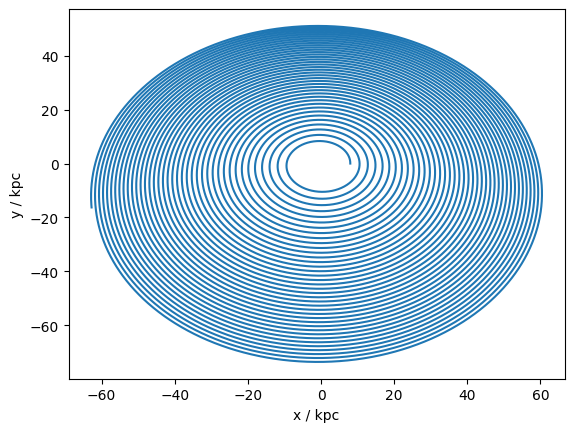

In [4]:
#eulers method
import matplotlib.pyplot as plt
import numpy as np
import math as ma

sim_size = 100000

x = np.zeros(sim_size)
y = np.zeros(sim_size)
vx = np.zeros(sim_size)
vy = np.zeros(sim_size)
E = np.zeros(sim_size)
x[0] = 8.0
y[0] = 0.0
vx[0] = 0.0
vy[0] = ma.sqrt((43007.10573 * 9) / 8) 

G = 43007.10573
M = 9
delta_t = 0.001

# a = -GM/r^3 * x


for i in range(sim_size-1):
    r = ma.sqrt(x[i]**2 + y[i]**2)
    v = ma.sqrt(vx[i]**2 + vy[i]**2)
    ax = -(G*M* x[i]) / (r**3)
    ay = -(G*M* y[i]) / (r**3)
    x[i+1] = x[i] + vx[i] * delta_t
    vx[i+1] = vx[i] + ax * delta_t
    y[i+1] = y[i] + vy[i] * delta_t
    vy[i+1] = vy[i] + ay * delta_t
    E[i] = 0.5 * v**2 - (G*M)/r


plt.plot(x,y)
plt.xlabel("x / kpc")
plt.ylabel("y / kpc")
plt.show()





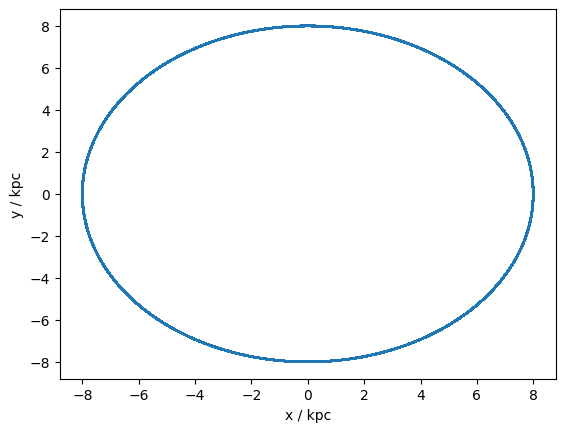

In [5]:
#Kick drift kick
import numpy as np
import math as ma

sim_size = 100000

x = np.zeros(sim_size)
y = np.zeros(sim_size)
vx = np.zeros(sim_size)
vy = np.zeros(sim_size)

x[0] = 8.0
y[0] = 0.0
vx[0] = 0.0
vy[0] = ma.sqrt((43007.10573 * 9) / 8) 

G = 43007.10573
M = 9
delta_t = 0.001

for i in range(sim_size -1):
    
    r = ma.sqrt(x[i]**2 + y[i]**2)
    v = ma.sqrt(vx[i]**2 + vy[i]**2)
    ax = -(G*M* x[i]) / (r**3)
    ay = -(G*M* y[i]) / (r**3)
    
    Vx_half = vx[i] + ax * (delta_t / 2)
    Vy_half = vy[i] + ay * (delta_t / 2)

    x[i+1] = x[i] + Vx_half * delta_t
    y[i+1] = y[i] + Vy_half * delta_t

    r = ma.sqrt(x[i+1]**2 + y[i+1]**2)
    ax = -(G*M* x[i+1]) / (r**3)
    ay = -(G*M* y[i+1]) / (r**3)

    vx[i+1] = Vx_half + ax * (delta_t / 2)
    vy[i+1] = Vy_half + ay * (delta_t / 2)
    
plt.plot(x,y)
plt.xlabel("x / kpc")
plt.ylabel("y / kpc")
plt.show()

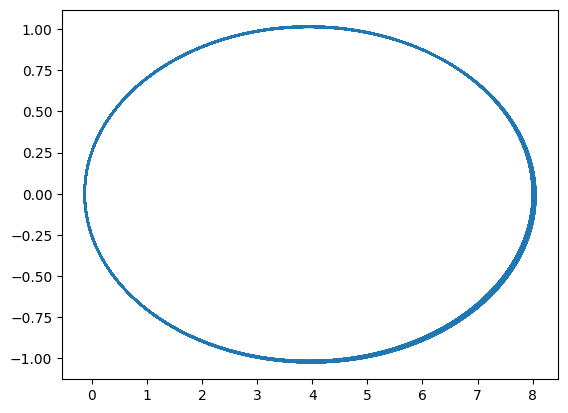

In [4]:
#Changing the time step

import numpy as np
import math as ma

sim_size = 100000

x = np.zeros(sim_size)
y = np.zeros(sim_size)
vx = np.zeros(sim_size)
vy = np.zeros(sim_size)

x[0] = 8.0
y[0] = 0.0
vy[0] = ma.sqrt((43007.10573 * 9) / 252) 
vx[0] = 0.0 

G = 43007.10573
M = 9
#delta_t = 0.001
long_n = 0.01

for i in range(sim_size -1):
    
    r = ma.sqrt(x[i]**2 + y[i]**2)
    v = ma.sqrt(vx[i]**2 + vy[i]**2)
    ax = -(G*M* x[i]) / (r**3)
    ay = -(G*M* y[i]) / (r**3)
    a = ma.sqrt(ay**2 + ax**2)
    delta_t = long_n * ma.sqrt(r/a)
    
    Vx_half = vx[i] + ax * (delta_t / 2)
    Vy_half = vy[i] + ay * (delta_t / 2)

    x[i+1] = x[i] + Vx_half * delta_t
    y[i+1] = y[i] + Vy_half * delta_t

    r = ma.sqrt(x[i+1]**2 + y[i+1]**2)
    ax = -(G*M* x[i+1]) / (r**3)
    ay = -(G*M* y[i+1]) / (r**3)

    vx[i+1] = Vx_half + ax * (delta_t / 2)
    vy[i+1] = Vy_half + ay * (delta_t / 2)
    
plt.plot(x,y)
plt.show()

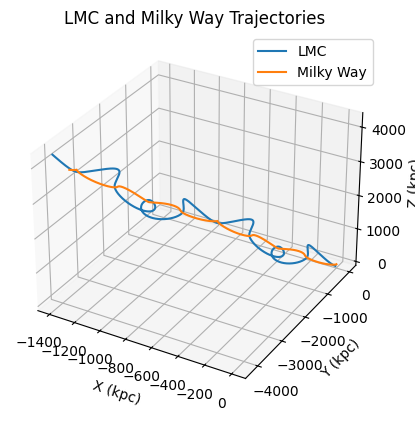

In [5]:
#Kick drift kick for milky way and LMC
import matplotlib.pyplot as plt
import numpy as np
import math as ma


size = 100000
sim_size = np.zeros(size)
#x,y,z,vx,vy,vz
LMC = np.zeros((6, size))
MW = np.zeros((6, size))



LMC[0,0] = -1.121105
LMC[1,0] = -40.105371
LMC[2,0] = -27.193136
LMC[3,0] = -71.393348
LMC[4,0] = -226.73068
LMC[5,0] = 211.651791



MW[0,0] = 0.0
MW[1,0] = 0.0
MW[2,0] = 0.0
MW[3,0] = 0.0
MW[4,0] = 0.0 
MW[5,0] = 0.0


G = 43007.10573
M_LMC = 15
M_MW = 80
delta_t = 0.001
rs_MW = 16
rs_LMC = 7.39
c_MW = 15.3
c_LMC = 20


for i in range(size - 1):
    
    r = ma.sqrt((MW[0,i] - LMC[0,i])**2 + (MW[1,i] - LMC[1,i])**2 + (MW[2,i] - LMC[2,i])**2)
    #NFW
    ax_LMC = (( (MW[0,i] - LMC[0,i]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    ay_LMC = (( (MW[1,i] - LMC[1,i]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    az_LMC = (( (MW[2,i] - LMC[2,i]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))

    ax_MW = -(( (MW[0,i] - LMC[0,i]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    ay_MW = -(( (MW[1,i] - LMC[1,i]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    az_MW = -(( (MW[2,i] - LMC[2,i]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))

    MW[0,i+1] = MW[0,i] + MW[3,i] * delta_t
    MW[3,i+1] = MW[3,i] + ax_MW * delta_t
    MW[1,i+1] = MW[1,i] + MW[4,i] * delta_t
    MW[4,i+1] = MW[4,i] + ay_MW * delta_t
    MW[2,i+1] = MW[2,i] + MW[5,i] * delta_t
    MW[5,i+1] = MW[5,i] + az_MW * delta_t

    LMC[0,i+1] = LMC[0,i] + LMC[3,i] * delta_t
    LMC[3,i+1] = LMC[3,i] + ax_LMC * delta_t
    LMC[1,i+1] = LMC[1,i] + LMC[4,i] * delta_t
    LMC[4,i+1] = LMC[4,i] + ay_LMC * delta_t
    LMC[2,i+1] = LMC[2,i] + LMC[5,i] * delta_t
    LMC[5,i+1] = LMC[5,i] + az_LMC * delta_t
    
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.plot(LMC[0, :], LMC[1, :], LMC[2, :], label='LMC')
ax.plot(MW[0, :], MW[1, :], MW[2, :], label='Milky Way')

ax.set_xlabel('X (kpc)')
ax.set_ylabel('Y (kpc)')
ax.set_zlabel('Z (kpc)')
ax.set_title('LMC and Milky Way Trajectories')
ax.legend()
plt.show()
   
    
    

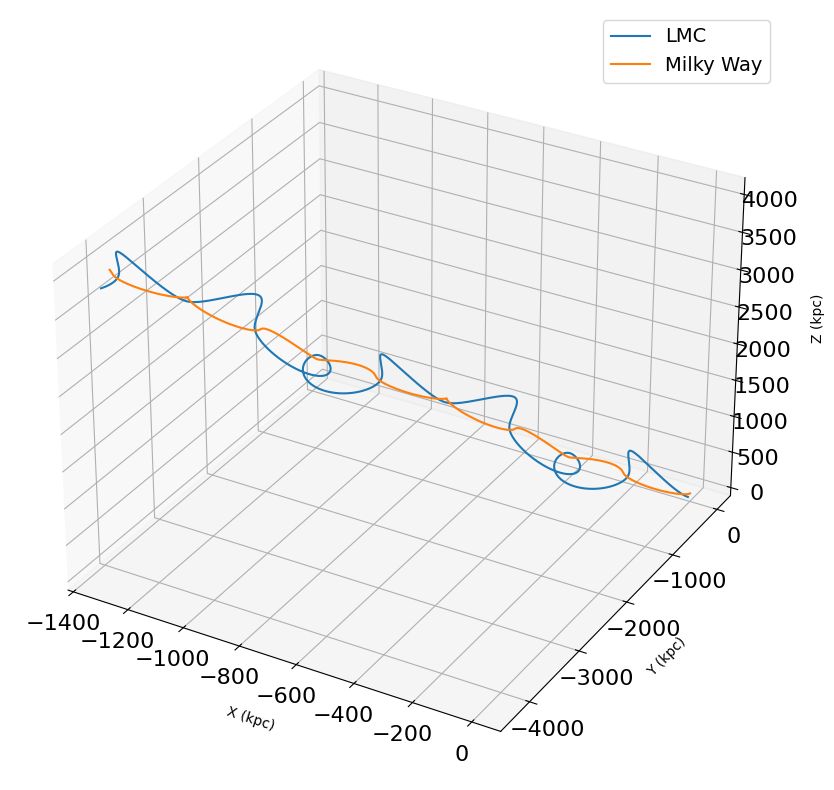

In [14]:
import matplotlib.pyplot as plt
import numpy as np
import math as ma

size = 100000
sim_size = np.zeros(size)
#x,y,z,vx,vy,vz
LMC = np.zeros((6, size))
MW = np.zeros((6, size))



LMC[0,0] = -1.121105
LMC[1,0] = -40.105371
LMC[2,0] = -27.193136
LMC[3,0] = -71.393348
LMC[4,0] = -226.73068
LMC[5,0] = 211.651791



MW[0,0] = 0.0
MW[1,0] = 0.0
MW[2,0] = 0.0
MW[3,0] = 0.0
MW[4,0] = 0.0 
MW[5,0] = 0.0


G = 43007.10573
M_LMC = 15
M_MW = 80
delta_t = 0.001
rs_MW = 16
rs_LMC = 7.39
c_MW = 15.3
c_LMC = 20


for i in range(size - 1):
    
    r = ma.sqrt((MW[0,i] - LMC[0,i])**2 + (MW[1,i] - LMC[1,i])**2 + (MW[2,i] - LMC[2,i])**2)
    ax_LMC = (( (MW[0,i] - LMC[0,i]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    ay_LMC = (( (MW[1,i] - LMC[1,i]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    az_LMC = (( (MW[2,i] - LMC[2,i]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    a_LMC = ma.sqrt((ax_LMC**2 + ay_LMC**2 + az_LMC**2))
    
    ax_MW = -(( (MW[0,i] - LMC[0,i]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    ay_MW = -(( (MW[1,i] - LMC[1,i]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    az_MW = -(( (MW[2,i] - LMC[2,i]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    a_MW = ma.sqrt((ax_MW**2 + ay_MW**2 + az_MW**2))

    VxMW_half = MW[3,i] + ax_MW * (delta_t / 2)
    VyMW_half = MW[4,i] + ay_MW * (delta_t / 2)
    VzMW_half = MW[5,i] + az_MW * (delta_t / 2)

    VxLMC_half = LMC[3,i] + ax_LMC * (delta_t / 2)
    VyLMC_half = LMC[4,i] + ay_LMC * (delta_t / 2)
    VzLMC_half = LMC[5,i] + az_LMC * (delta_t / 2)

    MW[0,i+1] = MW[0,i] + VxMW_half * delta_t
    MW[1,i+1] = MW[1,i] + VyMW_half * delta_t
    MW[2,i+1] = MW[2,i] + VzMW_half * delta_t 

    LMC[0,i+1] = LMC[0,i] + VxLMC_half * delta_t
    LMC[1,i+1] = LMC[1,i] + VyLMC_half * delta_t
    LMC[2,i+1] = LMC[2,i] + VzLMC_half * delta_t

    r = ma.sqrt((MW[0,i+1] - LMC[0,i+1])**2 + (MW[1,i+1] - LMC[1,i+1])**2 + (MW[2,i+1] - LMC[2,i+1])**2)
    ax_LMC = (( (MW[0,i+1] - LMC[0,i+1]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    ay_LMC = (( (MW[1,i+1] - LMC[1,i+1]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    az_LMC = (( (MW[2,i+1] - LMC[2,i+1]) * G * M_MW)/r**3) * (ma.log(1+(r/rs_MW))-(r/(r+rs_MW)))/(ma.log(1+c_MW)-(c_MW/(1+c_MW)))
    a_LMC = ma.sqrt((ax_LMC**2 + ay_LMC**2 + az_LMC**2))
    
    ax_MW = -(( (MW[0,i+1] - LMC[0,i+1]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    ay_MW = -(( (MW[1,i+1] - LMC[1,i+1]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    az_MW = -(( (MW[2,i+1] - LMC[2,i+1]) * G * M_LMC)/r**3) * (ma.log(1+(r/rs_LMC))-(r/(r+rs_LMC)))/(ma.log(1+c_LMC)-(c_LMC/(1+c_LMC)))
    a_MW = ma.sqrt((ax_MW**2 + ay_MW**2 + az_MW**2))
    #vx[i+1] = Vx_half + ax * (delta_t / 2)
    #vy[i+1] = Vy_half + ay * (delta_t / 2)

    MW[3,i+1] = VxMW_half + ax_MW * (delta_t / 2)
    MW[4,i+1] = VyMW_half + ay_MW * (delta_t / 2)
    MW[5,i+1] = VzMW_half + az_MW * (delta_t / 2)

    LMC[3,i+1] = VxLMC_half + ax_LMC * (delta_t / 2 )
    LMC[4,i+1] = VyLMC_half + ay_LMC * (delta_t / 2 )
    LMC[5,i+1] = VzLMC_half + az_LMC * (delta_t / 2 )
    
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.plot(LMC[0, :], LMC[1, :], LMC[2, :], label='LMC')
ax.plot(MW[0, :], MW[1, :], MW[2, :], label='Milky Way')

ax.set_xlabel('X (kpc)', labelpad=10)
ax.set_ylabel('Y (kpc)', labelpad=10)

ax.set_zlabel('')

# Manually add the Z-axis label
ax.text2D(1.04, 0.6, 'Z (kpc)',
          transform=ax.transAxes,
          rotation=90,
          verticalalignment='center')


ax.legend(fontsize=14)
ax.tick_params(axis='x', labelsize=16)
ax.tick_params(axis='y', labelsize=16)
ax.tick_params(axis='z', labelsize=16)
plt.tight_layout()
plt.show()

In [7]:
ma.log(20)

2.995732273553991